In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("seaborn-v0_8-poster")

In [2]:
n_cpu = 10
df = pd.DataFrame()
for i in range(n_cpu):
    df = pd.concat([df, pd.read_csv(f"../data/Nx=3_Ny=3_Ne=8_self_cap0.00_part{i}.csv")], ignore_index=True)
                   
df.to_csv(f"../data/Nx=3_Ny=3_Ne=8_self_cap0.00.csv", index=0)

In [3]:
# Params
scale_factor = 0.16

df  = pd.read_csv("../data/Nx=3_Ny=3_Ne=8_self_cap0.00.csv").iloc[:,[0,1,2,3,4,5,6,-2,-1]]
X   = df.iloc[:,:7].values
y   = df.iloc[:,-2].values
y_e = df.iloc[:,-1].values

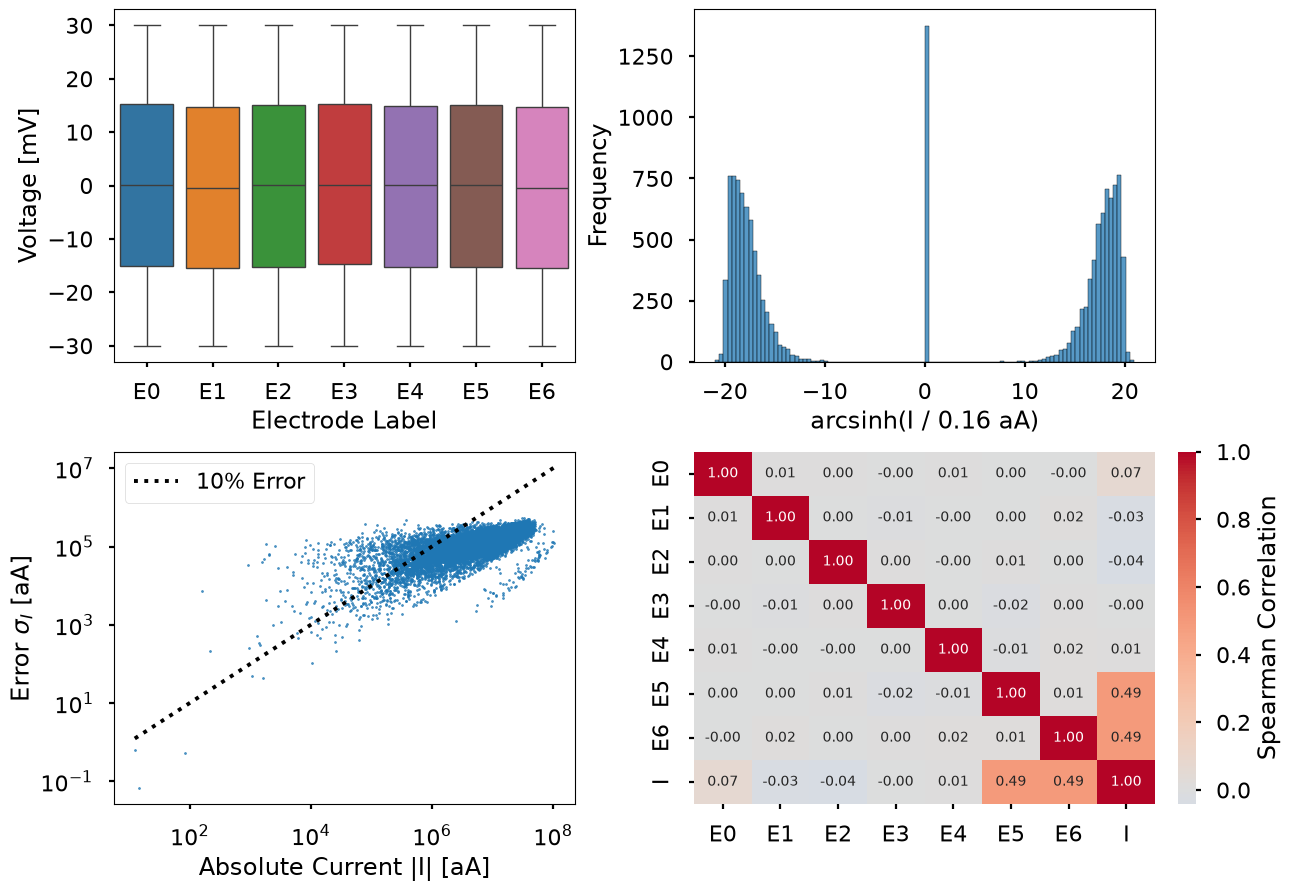

In [4]:
# Arcsinh scale
y_trans = np.arcsinh(df.iloc[:, -2] / scale_factor)

# Get conductive states
mask_conducting = (df.iloc[:, -2].abs() > scale_factor) & (df.iloc[:, -1] > 0)
I_cond = df.iloc[:, -2][mask_conducting].abs()
err_cond = df.iloc[:, -1][mask_conducting]

# Plot Config
fig, axes = plt.subplots(2, 2, layout='constrained')

# Phase Space Sample
sns.boxplot(data=df.iloc[:, :7]*1000, ax=axes[0, 0], fliersize=1)
axes[0, 0].set_xlabel("Electrode Label")
axes[0, 0].set_ylabel("Voltage [mV]")

# Current Distribution
sns.histplot(y_trans, bins=100, ax=axes[0, 1], kde=False)
axes[0, 1].set_xlabel("arcsinh(I / 0.16 aA)")
axes[0, 1].set_ylabel("Frequency")
# axes[0, 1].axvline(0, color='black', linestyle='--', linewidth=1)

# Signal-to-Noise
axes[1, 0].scatter(I_cond, err_cond, alpha=0.8, s=2)
axes[1, 0].set_xscale('log')
axes[1, 0].set_yscale('log')
axes[1, 0].set_xlabel("Absolute Current |I| [aA]")
axes[1, 0].set_ylabel("Error $\\sigma_I$ [aA]")
# Constant Signal-to-Noise (e.g. 10%)
axes[1, 0].plot([I_cond.min(), I_cond.max()], [I_cond.min()*0.1, I_cond.max()*0.1], 
                color='black', linestyle=':', label='10% Error')
axes[1, 0].legend()
# axes[1, 0].set_xlim(1e4)
# axes[1, 0].set_ylim(1e4)

# Correlation
df_corr = df.iloc[:, :7].copy()
df_corr['I'] = y_trans
corr = df_corr.corr(method='spearman')

ax = sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", ax=axes[1, 1], center=0, 
                 cbar_kws={'label': 'Spearman Correlation'})